# Pull Request Merge-Time Prediction by Programming Language
## One Feature-Engineered XGBoost Model Per Language

## Purpose

Earlier experiments showed that a single global model had difficulty predicting whether pull requests would merge **Fast**, **Medium**, or **Slow**.

One possible reason is that the dataset combines pull requests from very different programming-language ecosystems.

A Java PR, Python PR, TypeScript PR, or C++ PR may differ in:

- typical PR size
- repository structure
- test/build processes
- review practices
- file breadth
- configuration burden
- development workflow

Instead of forcing one model to learn all of these environments simultaneously, this notebook trains **one XGBoost classifier for each programming language**.

The central research question is:

> **Does merge-time classification become more accurate when separate models are trained within individual programming-language ecosystems?**

---

## Important design choice

We use only **one modeling approach**:

### XGBoost + engineered PR features

There is:

- no baseline model
- no baseline-vs-feature-engineered comparison
- no Logistic Regression
- no Random Forest

The experiment is focused specifically on whether **language-specific modeling** improves performance.

---

## Target

The outcome remains unchanged:

- **Fast**
- **Medium**
- **Slow**

The merge-time thresholds are calculated **once from the full dataset** so that every language model is predicting the same outcome definition.

This makes language-level accuracy directly comparable.

# 1. Imports and configuration

In [1]:
from pathlib import Path
import ast
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

# Minimum samples required before we train a language-specific model.
MIN_LANGUAGE_TRAIN_ROWS = 2_000
MIN_LANGUAGE_TEST_ROWS = 500

# Optional caps to keep runtime manageable.
MAX_TRAIN_ROWS_PER_LANGUAGE = 150_000
MAX_TEST_ROWS_PER_LANGUAGE = 75_000

# Number of languages to model.
TOP_N_LANGUAGES = 15

pd.set_option("display.max_columns", 150)
pd.set_option("display.max_colwidth", 150)

# 2. Load the dataset

In [2]:
data_dir = Path("../data")
file_path = data_dir / "prs_with_complexity.csv"

df = pd.read_csv(file_path)

print(f"Dataframe shape: {df.shape}")

print("\nColumns:")
print(df.columns.tolist())

df.head()

Dataframe shape: (1606726, 56)

Columns:
['customer_id', 'seat_count', 'available_customer_prs', 'repository_count', 'seat_group', 'pr_group', 'user_id', 'repository_id', 'pull_request_id', 'oid', 'title', 'body', 'combined_text_nlp', 'merge_day', 'merge_month', 'had_copilot_seat', 'files_added', 'files_deleted', 'files_modified', 'files_touched', 'lines_modified', 'code_lines_modified', 'config_lines_modified', 'lines_added_by_language', 'lines_deleted_by_language', 'languages_list', 'minutes_to_merge', 'num_reviewers', 'num_review_comments', 'is_code_pr', 'standardized_complexity_score', 'complexity_score', 'has_body', 'kw_feature', 'kw_bug_fix', 'kw_refactor', 'kw_documentation', 'kw_testing', 'kw_dependency', 'kw_security', 'kw_performance', 'kw_configuration', 'kw_release', 'kw_revert', 'keyword_categories', 'keyword_category_count', 'has_keyword_match', 'complexity_code_size', 'complexity_file_breadth', 'complexity_review_comments', 'complexity_reviewers', 'complexity_config', 'c

,customer_id,seat_count,available_customer_prs,repository_count,seat_group,pr_group,user_id,repository_id,pull_request_id,oid,title,body,combined_text_nlp,merge_day,merge_month,had_copilot_seat,files_added,files_deleted,files_modified,files_touched,lines_modified,code_lines_modified,config_lines_modified,lines_added_by_language,lines_deleted_by_language,languages_list,minutes_to_merge,num_reviewers,num_review_comments,is_code_pr,standardized_complexity_score,complexity_score,has_body,kw_feature,kw_bug_fix,kw_refactor,kw_documentation,kw_testing,kw_dependency,kw_security,kw_performance,kw_configuration,kw_release,kw_revert,keyword_categories,keyword_category_count,has_keyword_match,complexity_code_size,complexity_file_breadth,complexity_review_comments,complexity_reviewers,complexity_config,complexity_category_breadth,complexity_review_burden,pr_complexity_score,pr_complexity_level
0,11222,10484,140530,9427,4,5,99937741,1239475001,3779510455,d66433fe112ea9eb91db678c5c940c44e2c3c4ca,[Release] Develop to Master agent sse changes,## Purpose\r\nRelasing agent sse changes\r\n\r\n## JIRA\r\n[_JIRA Ticket_](https://paypal.atlassian.net/browse/DTPLATDQPF-8725)\r\n\r\n## Screensh...,[Release] Develop to Master agent sse changes ## Purpose\r\nRelasing agent sse changes\r\n\r\n## JIRA\r\n[_JIRA Ticket_](https://paypal.atlassian....,2026-06-01,2026-06-01,True,7,0,27,34,2152,2134,18,"{'YAML': 17.0, 'XML': None, 'C#': None, 'TSX': 1006.0, 'TypeScript': 984.0, 'Markdown': 1.0, 'JSON': None, 'OASv2-json': None, 'Ruby': None, 'Batc...","{'YAML': None, 'XML': None, 'C#': None, 'TSX': 98.0, 'TypeScript': 46.0, 'JSON': None, 'OASv2-json': None, 'Ruby': None, 'Ant Build System': None,...",['Markdown' 'TSX' 'TypeScript' 'YAML'],22,1,0,True,154.603561,95.0,True,True,True,True,False,True,False,False,False,False,True,False,"['feature', 'bug_fix', 'refactor', 'testing', 'release']",5,True,0.964378,0.928542,0.357786,0.419278,0.673683,0.855370,0.382383,76.63,Very High
1,11222,10484,140530,9427,4,5,267493148,1237611968,3702016153,3b9f626841c8840d59c095e8cf41f2e63800904a,Automating PR from script,Automating PR from script,Automating PR from script Automating PR from script,2026-05-18,2026-05-01,False,1,0,6,7,857,788,69,"{'YAML': None, 'XML': None, 'C#': None, 'TSX': None, 'TypeScript': None, 'Markdown': None, 'JSON': 65.0, 'OASv2-json': 400.0, 'Ruby': None, 'Batch...","{'YAML': None, 'XML': None, 'C#': None, 'TSX': None, 'TypeScript': None, 'JSON': 4.0, 'OASv2-json': 388.0, 'Ruby': None, 'Ant Build System': None,...",['JSON' 'OASv2-json'],0,0,0,True,24.613611,82.0,True,False,False,False,False,False,False,False,False,False,False,False,[],0,False,0.910080,0.714838,0.357786,0.117950,0.794805,0.087631,0.261852,57.41,High
2,11222,10484,140530,9427,4,5,192995331,1204482829,3609573181,65e71a42102caef1c52a57f3998cbc0487e0637d,fix: Update package-lock.json for developeruikit and bundlewatch removal,<!-- Provide a general summary of your changes in the Title above -->\r\n\r\nJIRA:\r\n\r\n## Description\r\n\r\n<!-- Describe your changes in deta...,fix: Update package-lock.json for developeruikit and bundlewatch removal <!-- Provide a general summary of your changes in the Title above -->\r\n...,2026-04-30,2026-04-01,True,0,0,1,1,168,0,168,"{'YAML': None, 'XML': None, 'C#': None, 'TSX': None, 'TypeScript': None, 'Markdown': None, 'JSON': 24.0, 'OASv2-json': None, 'Ruby': None, 'Batchf...","{'YAML': None, 'XML': None, 'C#': None, 'TSX': None, 'TypeScript': None, 'JSON': 144.0, 'OASv2-json': None, 'Ruby': None, 'Ant Build System': None...",['JSON'],16,1,0,False,-39.991961,55.0,True,True,True,False,True,True,True,False,False,False,True,False,"['feature', 'bug_fix', 'documentation', 'testing', 'dependency', 'release']",6,True,0.180068,0.149516,0.357786,0.419278,0.863838,0.913469,0.382383,40.29,Moderate
3,382,2036,4577,125,2,2,214534110,468367612,3726529045,841820a2f64d7ee86a4e786289c8ec80a246f448,Review: Bump versions for completion rename changes [ENG-19420],[ENG-19420],R

# 3. Clean the modeling population

In [3]:
if "minutes_to_merge" not in df.columns:
    raise KeyError("minutes_to_merge is required.")

df["minutes_to_merge"] = pd.to_numeric(
    df["minutes_to_merge"],
    errors="coerce"
)

if "merge_day" in df.columns:
    df["merge_day"] = pd.to_datetime(
        df["merge_day"],
        errors="coerce"
    )

df_ml = df[
    df["minutes_to_merge"].notna()
    & (df["minutes_to_merge"] > 0)
].copy()

df_ml["merge_hours"] = (
    df_ml["minutes_to_merge"] / 60
)

print(f"Eligible merged PRs: {len(df_ml):,}")

Eligible merged PRs: 1,423,078


# 4. Create one global Fast / Medium / Slow target

The target is created before splitting by programming language.

This is important.

If we calculated new tertiles for every language, then "Fast" might mean 30 minutes for one language and 6 hours for another. Accuracy would no longer be directly comparable.

Instead, every language uses the same global merge-time classes.

In [4]:
TARGET = "merge_time_class"

df_ml[TARGET] = pd.qcut(
    df_ml["minutes_to_merge"],
    q=3,
    labels=["Fast", "Medium", "Slow"],
    duplicates="drop"
)

print("Class counts:")
print(df_ml[TARGET].value_counts())

print("\nClass proportions:")
print(
    df_ml[TARGET]
    .value_counts(normalize=True)
    .round(3)
)

print("\nGlobal merge-time thresholds in hours:")
print(
    df_ml["merge_hours"]
    .quantile([0, 1/3, 2/3, 1])
)

Class counts:
merge_time_class
Fast      474513
Slow      474325
Medium    474240
Name: count, dtype: int64

Class proportions:
merge_time_class
Fast      0.333
Slow      0.333
Medium    0.333
Name: proportion, dtype: float64

Global merge-time thresholds in hours:
0.000000        0.016667
0.333333        0.683333
0.666667       22.966667
1.000000    30155.783333
Name: merge_hours, dtype: float64


# 5. Detect the complexity score

In [5]:
COMPLEXITY_SCORE_COL = None

for candidate in [
    "pr_complexity_score",
    "complexity_score",
]:
    if candidate in df_ml.columns:
        COMPLEXITY_SCORE_COL = candidate
        break

print("Complexity score:", COMPLEXITY_SCORE_COL)

Complexity score: pr_complexity_score


# 6. Create dominant programming language

We first try to infer the dominant language from `lines_added_by_language`.

Example:

`{'Python': 220, 'Shell': 10}`

becomes:

`Python`

If that column is unavailable, we fall back to the first value in `languages_list`.

In [6]:
def parse_dict(value):

    if isinstance(value, dict):
        return value

    if pd.isna(value):
        return {}

    if isinstance(value, str):
        try:
            parsed = ast.literal_eval(value)

            if isinstance(parsed, dict):
                return parsed

        except Exception:
            pass

    return {}


def parse_list(value):

    if isinstance(value, list):
        return value

    if pd.isna(value):
        return []

    if isinstance(value, str):
        try:
            parsed = ast.literal_eval(value)

            if isinstance(parsed, list):
                return parsed

        except Exception:
            pass

    return []


def get_dominant_language(row):

    if "lines_added_by_language" in row.index:

        language_dict = parse_dict(
            row["lines_added_by_language"]
        )

        if language_dict:
            try:
                return max(
                    language_dict,
                    key=lambda language: abs(
                        float(
                            language_dict[language]
                        )
                    )
                )
            except Exception:
                pass

    if "languages_list" in row.index:

        languages = parse_list(
            row["languages_list"]
        )

        if languages:
            return languages[0]

    return "Unknown"


df_ml["dominant_language"] = (
    df_ml.apply(
        get_dominant_language,
        axis=1
    )
)

print(
    df_ml["dominant_language"]
    .value_counts()
    .head(25)
)

dominant_language
YAML              213648
JSON               71943
Python             64404
HCL                56605
Markdown           48533
Java               41544
TypeScript         35970
C#                 33643
Maven POM          31515
XML                19433
SQL                18158
TSXTypeScript      16546
JSONYAML           15993
JavaScript         15889
TOML               15244
MarkdownYAML       14441
TSX                13762
Go                 10918
Kotlin             10696
JSONMarkdown       10604
Gradle             10434
MarkdownPython      9140
Dockerfile          8666
PythonYAML          8409
C#XML               7894
Name: count, dtype: int64


# 7. Optional: code PRs only

For the language-specific experiment, we focus on PRs identified as code PRs when that variable exists.

This reduces noise from documentation-only or other non-code changes.

In [7]:
if "is_code_pr" in df_ml.columns:

    code_values = (
        df_ml["is_code_pr"]
        .replace({
            True: 1,
            False: 0,
            "True": 1,
            "False": 0,
        })
    )

    code_values = pd.to_numeric(
        code_values,
        errors="coerce"
    )

    df_ml["is_code_pr"] = code_values

    df_ml = df_ml[
        df_ml["is_code_pr"] == 1
    ].copy()

print(f"Rows after code-PR filter: {len(df_ml):,}")

Rows after code-PR filter: 822,584


# 8. Chronological train/test split

Whenever possible, we train on earlier months and test on the latest month.

This is preferable to randomly mixing historical and future PRs.

In [8]:
if (
    "merge_day" in df_ml.columns
    and df_ml["merge_day"].notna().sum() > 0
):

    df_ml["merge_month"] = (
        df_ml["merge_day"]
        .dt.to_period("M")
    )

    months = sorted(
        df_ml["merge_month"]
        .dropna()
        .unique()
    )

    print("Available months:")
    print(months)

    if len(months) >= 2:

        test_month = months[-1]

        train_df = df_ml[
            df_ml["merge_month"] < test_month
        ].copy()

        test_df = df_ml[
            df_ml["merge_month"] == test_month
        ].copy()

        print(f"\nHeld-out test month: {test_month}")

    else:

        train_df, test_df = train_test_split(
            df_ml,
            test_size=0.20,
            stratify=df_ml[TARGET],
            random_state=RANDOM_STATE
        )

        print(
            "Only one month available. "
            "Using stratified random split."
        )

else:

    train_df, test_df = train_test_split(
        df_ml,
        test_size=0.20,
        stratify=df_ml[TARGET],
        random_state=RANDOM_STATE
    )

    print(
        "merge_day unavailable. "
        "Using stratified random split."
    )

print(f"Training rows: {len(train_df):,}")
print(f"Testing rows:  {len(test_df):,}")

Available months:
[Period('2026-04', 'M'), Period('2026-05', 'M'), Period('2026-06', 'M')]

Held-out test month: 2026-06
Training rows: 538,998
Testing rows:  283,586


# 9. Feature engineering

Every language-specific XGBoost model receives the same feature definitions.

We create:

### Size transformations
- log code lines modified
- log configuration lines modified
- log files touched
- log files added/deleted/modified

### PR shape
- lines per file
- files per 100 lines
- configuration-change share

### Interactions
- code size × file breadth
- code size × Copilot seat
- complexity × Copilot seat

These help represent different forms of PR complexity rather than relying only on raw LOC.

In [9]:
def engineer_features(data):

    data = data.copy()

    for col in [
        "had_copilot_seat",
        "is_code_pr",
    ]:

        if col in data.columns:

            data[col] = (
                data[col]
                .replace({
                    True: 1,
                    False: 0,
                    "True": 1,
                    "False": 0,
                })
            )

            data[col] = pd.to_numeric(
                data[col],
                errors="coerce"
            )

    # Log transforms
    for col in [
        "code_lines_modified",
        "config_lines_modified",
        "lines_modified",
        "files_touched",
        "files_added",
        "files_deleted",
        "files_modified",
    ]:

        if col in data.columns:

            values = pd.to_numeric(
                data[col],
                errors="coerce"
            ).clip(lower=0)

            data[f"log_{col}"] = (
                np.log1p(values)
            )

    # Lines per file / files per 100 lines
    if (
        "code_lines_modified" in data.columns
        and "files_touched" in data.columns
    ):

        lines = pd.to_numeric(
            data["code_lines_modified"],
            errors="coerce"
        )

        files = pd.to_numeric(
            data["files_touched"],
            errors="coerce"
        )

        data["lines_per_file"] = (
            lines / (files + 1)
        )

        data["files_per_100_lines"] = (
            100 * files / (lines + 1)
        )

    # Configuration share
    if (
        "config_lines_modified" in data.columns
        and "code_lines_modified" in data.columns
    ):

        config = pd.to_numeric(
            data["config_lines_modified"],
            errors="coerce"
        ).fillna(0)

        code_lines = pd.to_numeric(
            data["code_lines_modified"],
            errors="coerce"
        ).fillna(0)

        data["config_change_share"] = (
            config
            / (
                config
                + code_lines
                + 1
            )
        )

    # Size × breadth
    if (
        "log_code_lines_modified"
        in data.columns
        and "log_files_touched"
        in data.columns
    ):

        data["log_lines_x_log_files"] = (
            data["log_code_lines_modified"]
            * data["log_files_touched"]
        )

    # Copilot interaction
    if (
        "had_copilot_seat" in data.columns
        and "log_code_lines_modified"
        in data.columns
    ):

        data["log_lines_x_copilot"] = (
            data["log_code_lines_modified"]
            * data["had_copilot_seat"]
        )

    # Complexity × Copilot
    if (
        COMPLEXITY_SCORE_COL is not None
        and COMPLEXITY_SCORE_COL
        in data.columns
        and "had_copilot_seat"
        in data.columns
    ):

        data["complexity_x_copilot"] = (
            pd.to_numeric(
                data[
                    COMPLEXITY_SCORE_COL
                ],
                errors="coerce"
            )
            * data["had_copilot_seat"]
        )

    return data


train_df = engineer_features(
    train_df
)

test_df = engineer_features(
    test_df
)

# 10. Select model features

In [10]:
feature_candidates = [
    "code_lines_modified",
    "config_lines_modified",
    "files_touched",
    "files_added",
    "files_deleted",
    "files_modified",
    "had_copilot_seat",

    COMPLEXITY_SCORE_COL,

    "log_code_lines_modified",
    "log_config_lines_modified",
    "log_files_touched",
    "log_files_added",
    "log_files_deleted",
    "log_files_modified",

    "lines_per_file",
    "files_per_100_lines",
    "config_change_share",

    "log_lines_x_log_files",
    "log_lines_x_copilot",
    "complexity_x_copilot",
]

FEATURES = [
    feature
    for feature in feature_candidates
    if feature is not None
    and feature in train_df.columns
]

print(
    f"Using {len(FEATURES)} model features:"
)

print(FEATURES)

Using 20 model features:
['code_lines_modified', 'config_lines_modified', 'files_touched', 'files_added', 'files_deleted', 'files_modified', 'had_copilot_seat', 'pr_complexity_score', 'log_code_lines_modified', 'log_config_lines_modified', 'log_files_touched', 'log_files_added', 'log_files_deleted', 'log_files_modified', 'lines_per_file', 'files_per_100_lines', 'config_change_share', 'log_lines_x_log_files', 'log_lines_x_copilot', 'complexity_x_copilot']


# 11. Identify languages with enough data

We select the most common languages from the **training data only**.

A language must also have enough observations in the held-out test period.

In [11]:
train_language_counts = (
    train_df[
        "dominant_language"
    ]
    .replace(
        "Unknown",
        np.nan
    )
    .dropna()
    .value_counts()
)

candidate_languages = (
    train_language_counts
    .head(
        TOP_N_LANGUAGES
    )
    .index
    .tolist()
)

language_summary = []

eligible_languages = []

for language in candidate_languages:

    train_count = (
        train_df[
            "dominant_language"
        ]
        .eq(language)
        .sum()
    )

    test_count = (
        test_df[
            "dominant_language"
        ]
        .eq(language)
        .sum()
    )

    eligible = (
        train_count
        >= MIN_LANGUAGE_TRAIN_ROWS
        and
        test_count
        >= MIN_LANGUAGE_TEST_ROWS
    )

    language_summary.append(
        {
            "language":
                language,
            "train_rows":
                train_count,
            "test_rows":
                test_count,
            "eligible":
                eligible,
        }
    )

    if eligible:
        eligible_languages.append(
            language
        )

language_summary_df = pd.DataFrame(
    language_summary
)

language_summary_df

,language,train_rows,test_rows,eligible
0,Python,42292,22112,True
1,HCL,37304,19301,True
2,Java,27753,13791,True
3,TypeScript,23561,12409,True
4,C#,22129,11514,True
5,Maven POM,20662,10853,True
6,SQL,12198,5960,True
7,TSXTypeScript,10744,5802,True
8,JavaScript,10727,5162,True
9,TSX,9075,4687,True


# 12. Import XGBoost

In [12]:
try:
    from xgboost import XGBClassifier

    print(
        "XGBoost imported successfully."
    )

except ImportError:

    raise ImportError(
        "Install XGBoost with: pip install xgboost"
    )

XGBoost imported successfully.


# 13. Helper for stratified sampling

Very large language groups are capped while preserving the Fast / Medium / Slow class distribution.

In [13]:
def stratified_cap(
    data,
    max_rows
):

    if (
        max_rows is None
        or len(data) <= max_rows
    ):
        return data.copy()

    if (
        data[TARGET]
        .value_counts()
        .min()
        < 2
    ):
        return data.copy()

    _, sampled = train_test_split(
        data,
        test_size=max_rows,
        stratify=data[TARGET],
        random_state=RANDOM_STATE
    )

    return sampled.reset_index(
        drop=True
    )

# 14. Train one XGBoost model for every language

Each programming language receives its **own independent model**.

The models do not share trees or parameters.

For example:

- Python PRs → Python XGBoost model
- Java PRs → Java XGBoost model
- TypeScript PRs → TypeScript XGBoost model

This allows the model to learn language-specific relationships between PR structure and merge time.

In [14]:
label_map = {
    "Fast": 0,
    "Medium": 1,
    "Slow": 2,
}

reverse_label_map = {
    0: "Fast",
    1: "Medium",
    2: "Slow",
}

language_results = []
class_results = []
confusion_matrices = {}

for language in eligible_languages:

    print(
        "\n"
        + "=" * 75
    )

    print(
        f"LANGUAGE: {language}"
    )

    print(
        "=" * 75
    )

    train_language = train_df[
        train_df[
            "dominant_language"
        ] == language
    ].copy()

    test_language = test_df[
        test_df[
            "dominant_language"
        ] == language
    ].copy()

    # Require all three classes
    if (
        train_language[
            TARGET
        ].nunique()
        < 3
    ):

        print(
            "Skipping: not all three classes "
            "are available in training data."
        )

        continue

    train_language = stratified_cap(
        train_language,
        MAX_TRAIN_ROWS_PER_LANGUAGE
    )

    test_language = stratified_cap(
        test_language,
        MAX_TEST_ROWS_PER_LANGUAGE
    )

    X_train = (
        train_language[
            FEATURES
        ]
        .copy()
    )

    X_test = (
        test_language[
            FEATURES
        ]
        .copy()
    )

    y_train_text = (
        train_language[
            TARGET
        ]
        .astype(str)
    )

    y_test_text = (
        test_language[
            TARGET
        ]
        .astype(str)
    )

    y_train = (
        y_train_text
        .map(
            label_map
        )
        .astype(int)
    )

    # Fill missing values using this
    # language's training medians only.
    medians = X_train.median(
        numeric_only=True
    )

    X_train = X_train.fillna(
        medians
    )

    X_test = X_test.fillna(
        medians
    )

    # --------------------------------------------------
    # Language-specific XGBoost
    # --------------------------------------------------

    model = XGBClassifier(
        n_estimators=1200,
        learning_rate=0.045,
        max_depth=8,
        min_child_weight=5,
        subsample=0.90,
        colsample_bytree=0.90,
        gamma=0.03,
        reg_alpha=0.05,
        reg_lambda=1.2,
        objective="multi:softprob",
        num_class=3,
        eval_metric="mlogloss",
        tree_method="hist",
        n_jobs=-1,
        random_state=RANDOM_STATE
    )

    model.fit(
        X_train,
        y_train,
        verbose=False
    )

    pred_numeric = model.predict(
        X_test
    )

    pred = (
        pd.Series(
            pred_numeric
        )
        .map(
            reverse_label_map
        )
        .values
    )

    # --------------------------------------------------
    # Overall language results
    # --------------------------------------------------

    accuracy = accuracy_score(
        y_test_text,
        pred
    )

    balanced_accuracy = (
        balanced_accuracy_score(
            y_test_text,
            pred
        )
    )

    macro_f1 = f1_score(
        y_test_text,
        pred,
        average="macro"
    )

    weighted_f1 = f1_score(
        y_test_text,
        pred,
        average="weighted"
    )

    language_results.append(
        {
            "language":
                language,
            "train_rows":
                len(train_language),
            "test_rows":
                len(test_language),
            "accuracy":
                accuracy,
            "balanced_accuracy":
                balanced_accuracy,
            "macro_f1":
                macro_f1,
            "weighted_f1":
                weighted_f1,
        }
    )

    # --------------------------------------------------
    # Per-class results
    # --------------------------------------------------

    report = classification_report(
        y_test_text,
        pred,
        output_dict=True,
        zero_division=0
    )

    for class_name in [
        "Fast",
        "Medium",
        "Slow"
    ]:

        class_results.append(
            {
                "language":
                    language,
                "class":
                    class_name,
                "precision":
                    report[
                        class_name
                    ][
                        "precision"
                    ],
                "recall":
                    report[
                        class_name
                    ][
                        "recall"
                    ],
                "f1":
                    report[
                        class_name
                    ][
                        "f1-score"
                    ],
            }
        )

    # --------------------------------------------------
    # Confusion matrix
    # --------------------------------------------------

    labels = [
        "Fast",
        "Medium",
        "Slow"
    ]

    cm = confusion_matrix(
        y_test_text,
        pred,
        labels=labels
    )

    confusion_matrices[
        language
    ] = pd.DataFrame(
        cm,
        index=[
            f"Actual {x}"
            for x in labels
        ],
        columns=[
            f"Predicted {x}"
            for x in labels
        ]
    )

    print(
        f"Accuracy: {accuracy:.3f}"
    )

    print(
        f"Macro F1: {macro_f1:.3f}"
    )

language_results_df = (
    pd.DataFrame(
        language_results
    )
    .sort_values(
        "accuracy",
        ascending=False
    )
    .reset_index(drop=True)
)

class_results_df = pd.DataFrame(
    class_results
)

language_results_df


LANGUAGE: Python
Accuracy: 0.455
Macro F1: 0.443

LANGUAGE: HCL
Accuracy: 0.466
Macro F1: 0.403

LANGUAGE: Java
Accuracy: 0.439
Macro F1: 0.441

LANGUAGE: TypeScript
Accuracy: 0.423
Macro F1: 0.419

LANGUAGE: C#
Accuracy: 0.441
Macro F1: 0.437

LANGUAGE: Maven POM
Accuracy: 0.437
Macro F1: 0.433

LANGUAGE: SQL
Accuracy: 0.452
Macro F1: 0.386

LANGUAGE: TSXTypeScript
Accuracy: 0.425
Macro F1: 0.418

LANGUAGE: JavaScript
Accuracy: 0.417
Macro F1: 0.408

LANGUAGE: TSX
Accuracy: 0.451
Macro F1: 0.421

LANGUAGE: Go
Accuracy: 0.428
Macro F1: 0.430

LANGUAGE: Kotlin
Accuracy: 0.456
Macro F1: 0.438

LANGUAGE: Gradle
Accuracy: 0.459
Macro F1: 0.446

LANGUAGE: Dockerfile
Accuracy: 0.439
Macro F1: 0.435

LANGUAGE: Swift
Accuracy: 0.484
Macro F1: 0.409


,language,train_rows,test_rows,accuracy,balanced_accuracy,macro_f1,weighted_f1
0,Swift,4744,2347,0.484448,0.407280,0.409021,0.477868
1,HCL,37304,19301,0.465986,0.410844,0.403314,0.438058
2,Gradle,6651,3783,0.459159,0.453925,0.445846,0.453187
3,Kotlin,7183,3513,0.455736,0.434457,0.437593,0.453604
4,Python,42292,22112,0.455228,0.443690,0.442923,0.449512
5,SQL,12198,5960,0.451678,0.388745,0.385653,0.433774
6,TSX,9075,4687,0.451248,0.420330,0.420728,0.447968
7,C#,22129,11514,0.440855,0.436976,0.436883,0.437965
8,Dockerfile,5685,2981,0.439114,0.434604,0.434555,0.437453
9,Java,27753,13791,0.438982,0.441075,0.440768,0.438704


# 15. Rank languages by prediction accuracy

This is the primary result.

If some languages are substantially more predictable than others, it suggests that the relationship between PR characteristics and merge-time behavior differs across programming ecosystems.

In [15]:
language_results_df[
    [
        "language",
        "accuracy",
        "balanced_accuracy",
        "macro_f1",
        "train_rows",
        "test_rows",
    ]
]

,language,accuracy,balanced_accuracy,macro_f1,train_rows,test_rows
0,Swift,0.484448,0.407280,0.409021,4744,2347
1,HCL,0.465986,0.410844,0.403314,37304,19301
2,Gradle,0.459159,0.453925,0.445846,6651,3783
3,Kotlin,0.455736,0.434457,0.437593,7183,3513
4,Python,0.455228,0.443690,0.442923,42292,22112
5,SQL,0.451678,0.388745,0.385653,12198,5960
6,TSX,0.451248,0.420330,0.420728,9075,4687
7,C#,0.440855,0.436976,0.436883,22129,11514
8,Dockerfile,0.439114,0.434604,0.434555,5685,2981
9,Java,0.438982,0.441075,0.440768,27753,13791


# 16. Plot accuracy by programming language

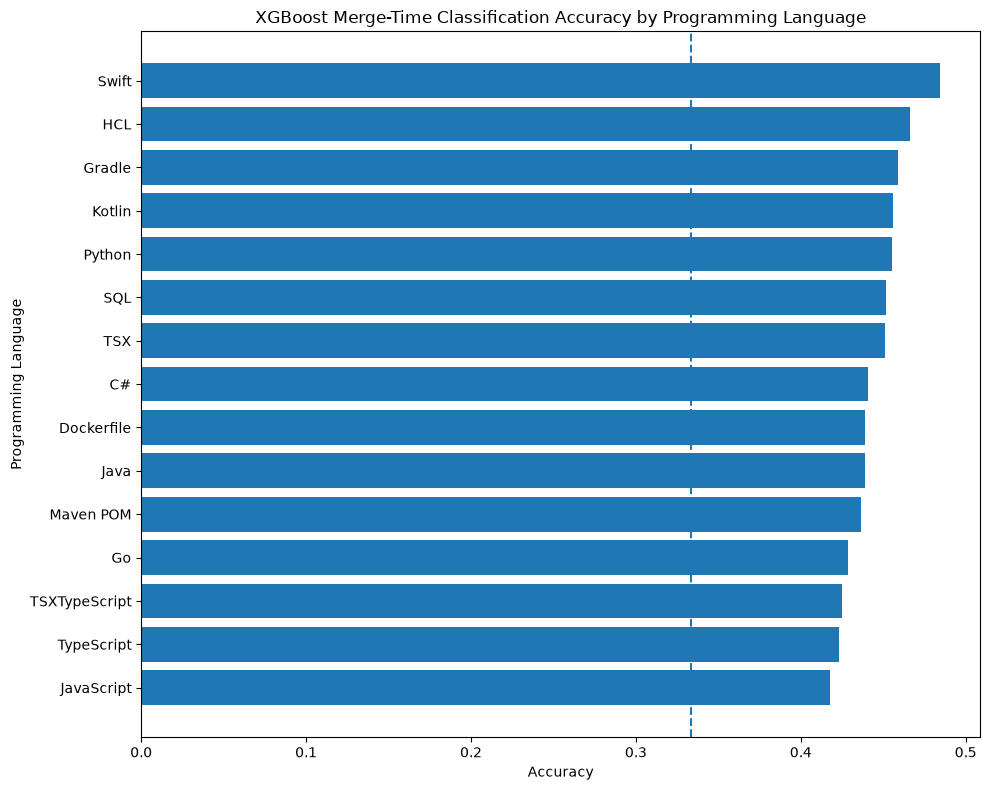

In [16]:
plot_df = (
    language_results_df
    .sort_values(
        "accuracy"
    )
)

fig, ax = plt.subplots(
    figsize=(10, 8)
)

ax.barh(
    plot_df["language"],
    plot_df["accuracy"]
)

ax.axvline(
    1 / 3,
    linestyle="--"
)

ax.set_title(
    "XGBoost Merge-Time Classification Accuracy by Programming Language"
)

ax.set_xlabel(
    "Accuracy"
)

ax.set_ylabel(
    "Programming Language"
)

plt.tight_layout()
plt.show()

# 17. Compare accuracy with sample size

A language with very high accuracy but only a small number of PRs should be interpreted cautiously.

This plot helps determine whether strong results are being driven by tiny subsets.

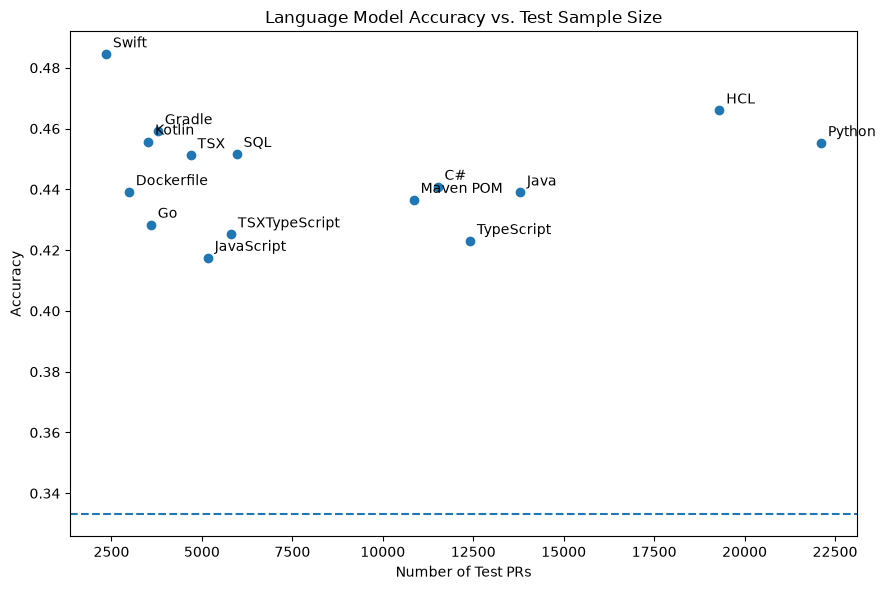

In [17]:
fig, ax = plt.subplots(
    figsize=(9, 6)
)

ax.scatter(
    language_results_df[
        "test_rows"
    ],
    language_results_df[
        "accuracy"
    ]
)

for _, row in (
    language_results_df
    .iterrows()
):

    ax.annotate(
        row["language"],
        (
            row["test_rows"],
            row["accuracy"]
        ),
        xytext=(5, 5),
        textcoords="offset points"
    )

ax.axhline(
    1 / 3,
    linestyle="--"
)

ax.set_title(
    "Language Model Accuracy vs. Test Sample Size"
)

ax.set_xlabel(
    "Number of Test PRs"
)

ax.set_ylabel(
    "Accuracy"
)

plt.tight_layout()
plt.show()

# 18. Fast / Medium / Slow recall by language

Overall accuracy may hide important differences.

For example, a model might classify:

- Fast PRs well
- Slow PRs well
- Medium PRs poorly

This table helps diagnose that behavior separately for every language.

In [18]:
recall_by_language = (
    class_results_df
    .pivot(
        index="language",
        columns="class",
        values="recall"
    )
)

recall_by_language

class,Fast,Medium,Slow
language,,,
C#,0.520343,0.455983,0.334602
Dockerfile,0.487032,0.467681,0.349099
Go,0.469912,0.395142,0.423549
Gradle,0.451572,0.579451,0.330753
HCL,0.727380,0.296972,0.208180
Java,0.513879,0.398300,0.411044
JavaScript,0.542570,0.363586,0.322712
Kotlin,0.330275,0.542062,0.431034
Maven POM,0.525501,0.411713,0.369734


# 19. Languages where Fast and Slow are easier than Medium

This can help determine whether class-boundary ambiguity is still the main issue.

In [19]:
if not recall_by_language.empty:

    recall_diagnostic = (
        recall_by_language
        .copy()
    )

    recall_diagnostic[
        "extreme_avg_recall"
    ] = (
        recall_diagnostic[
            ["Fast", "Slow"]
        ]
        .mean(axis=1)
    )

    recall_diagnostic[
        "extreme_vs_medium_gap"
    ] = (
        recall_diagnostic[
            "extreme_avg_recall"
        ]
        -
        recall_diagnostic[
            "Medium"
        ]
    )

    recall_diagnostic = (
        recall_diagnostic
        .sort_values(
            "extreme_vs_medium_gap",
            ascending=False
        )
    )

    recall_diagnostic

# 20. View a language-specific confusion matrix

Change `LANGUAGE_TO_VIEW` to inspect a particular language.

In [20]:
if len(language_results_df):

    LANGUAGE_TO_VIEW = (
        language_results_df
        .iloc[0][
            "language"
        ]
    )

    print(
        "Viewing:",
        LANGUAGE_TO_VIEW
    )

    display(
        confusion_matrices[
            LANGUAGE_TO_VIEW
        ]
    )

Viewing: Swift


,Predicted Fast,Predicted Medium,Predicted Slow
Actual Fast,48,190,75
Actual Medium,100,493,385
Actual Slow,60,400,596


# 21. How to interpret the experiment

## Scenario A — Several languages reach 55–70%

This would suggest that language-specific modeling removes meaningful heterogeneity from the global dataset.

A possible interpretation:

> Merge-time outcomes became substantially more predictable when models were trained separately within programming-language ecosystems, suggesting that the relationship between PR structure and delivery speed varies by development context.

---

## Scenario B — One or two languages perform very well

This could identify particular ecosystems where PR complexity has a clearer relationship with merge behavior.

Those languages would be good candidates for deeper analysis.

---

## Scenario C — Every language stays around 40–45%

Then language heterogeneity was probably not the main reason the global model struggled.

That would strengthen the conclusion that the currently observed PR features provide limited information about merge time.

---

## Scenario D — Fast and Slow recall are good, Medium recall remains low

This would suggest that models recognize clearly fast and clearly slow PRs but have difficulty with borderline cases around the tertile thresholds.

# 22. What exactly is this ML experiment describing?

The model is not defining PR complexity.

Instead, for each programming language it asks:

> **How much information do PR complexity and structural characteristics provide about whether a PR will eventually merge Fast, Medium, or Slow?**

Comparing languages then asks whether that predictive relationship differs across software-development ecosystems.

# 23. Save results

In [21]:
OUTPUT_DIR = Path(
    "../ml_outputs/language_xgboost"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

language_summary_df.to_csv(
    OUTPUT_DIR
    / "language_sample_sizes.csv",
    index=False
)

language_results_df.to_csv(
    OUTPUT_DIR
    / "xgboost_results_by_language.csv",
    index=False
)

class_results_df.to_csv(
    OUTPUT_DIR
    / "xgboost_class_metrics_by_language.csv",
    index=False
)

if "recall_diagnostic" in globals():

    recall_diagnostic.to_csv(
        OUTPUT_DIR
        / "language_recall_diagnostic.csv"
    )

print(
    f"Saved outputs to: "
    f"{OUTPUT_DIR.resolve()}"
)

Saved outputs to: /Users/syd-kiwi/Code/pr-complexity-analysis/ml_outputs/language_xgboost


# 24. Send these results back

The most useful files are:

1. `xgboost_results_by_language.csv`
2. `xgboost_class_metrics_by_language.csv`
3. `language_sample_sizes.csv`

The first file will immediately show whether separate language models can push accuracy meaningfully beyond the global ~40% result.